# Solver Loss Curves

This notebook compares three methods in a fixed order:

1. Zero solver interaction history
2. NN solver history
3. Trust-region solver history
4. Final loss comparison

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")

RESULTS_DIR = Path("results")
INTERACTION_HISTORY_CSV = Path("interaction_history.csv")
NN_HISTORY_CSV = RESULTS_DIR / "NN_solver_history.csv"

## 1. Zero Solver Interaction History

Load `interaction_history.csv` from `zero_solver.py` and compute the best-so-far upper objective.

In [2]:
zero_df = pd.read_csv(INTERACTION_HISTORY_CSV)
required_cols = {"interaction", "upper_objective"}
missing_cols = required_cols.difference(zero_df.columns)
if missing_cols:
    raise ValueError(f"Missing columns in {INTERACTION_HISTORY_CSV}: {sorted(missing_cols)}")

zero_df = zero_df.sort_values("interaction").reset_index(drop=True)
zero_df["best_so_far_loss"] = zero_df["upper_objective"].cummin()

print(f"Loaded zero solver history: {INTERACTION_HISTORY_CSV}")
display(zero_df.head())
display(zero_df.tail())

Loaded zero solver history: interaction_history.csv


,interaction,upper_objective,best_so_far_loss
0,1,39.797283,39.797283
1,2,40.124158,39.797283
2,3,39.029831,39.029831
3,4,39.426017,39.029831
4,5,38.632141,38.632141


,interaction,upper_objective,best_so_far_loss
12995,12996,33.070438,33.070438
12996,12997,33.070438,33.070438
12997,12998,33.070438,33.070438
12998,12999,33.070438,33.070438
12999,13000,33.070438,33.070438


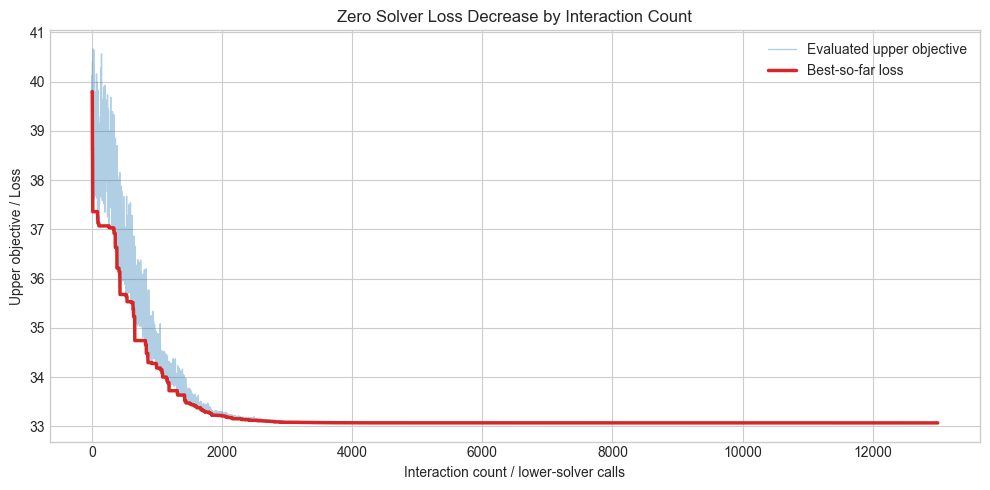

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    zero_df["interaction"],
    zero_df["upper_objective"],
    linewidth=1.0,
    alpha=0.35,
    label="Evaluated upper objective",
)
ax.plot(
    zero_df["interaction"],
    zero_df["best_so_far_loss"],
    linewidth=2.5,
    color="tab:red",
    label="Best-so-far loss",
)

ax.set_xlabel("Interaction count / lower-solver calls")
ax.set_ylabel("Upper objective / Loss")
ax.set_title("Zero Solver Loss Decrease by Interaction Count")
ax.legend()
fig.tight_layout()
plt.show()

## 2. NN Solver History

Load `results/NN_solver_history.csv`. The final comparison uses the last non-null `true_loss` as a horizontal dashed line.

In [4]:
nn_df = pd.read_csv(NN_HISTORY_CSV)
if "true_loss" not in nn_df.columns:
    raise ValueError(
        f"{NN_HISTORY_CSV} does not contain a 'true_loss' column. "
        "Rerun NN_solver.py after enabling true-loss logging."
    )

nn_df = nn_df.sort_values("iteration").reset_index(drop=True)
nn_true_loss_series = nn_df["true_loss"].dropna()
if nn_true_loss_series.empty:
    raise ValueError(f"No non-null true_loss values found in {NN_HISTORY_CSV}")

nn_true_loss = float(nn_true_loss_series.iloc[-1])
print(f"Loaded NN solver history: {NN_HISTORY_CSV}")
print(f"NN solver true loss used for comparison: {nn_true_loss:.6f}")
display(nn_df.tail())

Loaded NN solver history: results/NN_solver_history.csv
NN solver true loss used for comparison: 34.520278


,iteration,loss,obj,eq_pen,ineq_pen,soc_pen,bound_pen,true_loss,pi_0,pi_1,...,pi_14,pi_15,pi_16,pi_17,pi_18,pi_19,pi_20,pi_21,pi_22,pi_23
45,4500,29.277946,23.238270,0.005918,0.0,0.001168,0.000507,34.514947,0.981308,0.855764,...,0.997610,0.958694,0.988389,0.923746,1.018090,1.058328,0.987333,1.030414,1.011328,0.843947
46,4600,29.325026,23.234228,0.005969,0.0,0.001167,0.000521,34.516479,0.979512,0.855155,...,0.997064,0.958789,0.987702,0.923739,1.018702,1.058385,0.987253,1.030630,1.011266,0.844483
47,4700,30.337345,23.240726,0.006972,0.0,0.001192,0.000521,34.521711,0.979742,0.855552,...,0.995982,0.959259,0.987497,0.922981,1.018628,1.058587,0.988219,1.030791,1.012127,0.843738
48,4800,30.317217,23.224792,0.006966,0.0,0.001210,0.000526,34.525590,0.980689,0.853916,...,0.995171,0.959060,0.987605,0.923204,1.019762,1.058484,0.986627,1.030641,1.012299,0.843463
49,4900,31.601377,23.245895,0.008224,0.0,0.001258,0.000549,34.520278,0.979718,0.856677,...,0.997889,0.958640,0.988280,0.923377,1.019314,1.057917,0.988523,1.030816,1.010425,0.844304


In [35]:
TRUST_REGION_HISTORY_CSV = None  # Set to a Path to use a specific trust-region run.
TRUST_REGION_LOWER_CALLS_PER_ITER = 60

if TRUST_REGION_HISTORY_CSV is None:
    history_files = sorted(RESULTS_DIR.glob("trust_region_history_*.csv"))
    if not history_files:
        raise FileNotFoundError("No trust_region_history_*.csv files found in results/")
    TRUST_REGION_HISTORY_CSV = history_files[-1]

tr_df = pd.read_csv(TRUST_REGION_HISTORY_CSV).copy()
tr_df["accepted"] = tr_df["decision"].str.startswith("accept")

best_values = []
best = tr_df.loc[0, "F_current"] if len(tr_df) else np.nan
for _, row in tr_df.iterrows():
    if row["accepted"]:
        best = min(best, row["F_candidate"])
    best_values.append(best)
tr_df["best_true_objective"] = best_values

print(f"Loaded trust-region history: {TRUST_REGION_HISTORY_CSV}")
display(tr_df.head())
display(tr_df[["k", "F_current", "F_candidate", "best_true_objective", "decision", "rho", "R"]].tail())

Loaded trust-region history: results/trust_region_history_20260611-224003.csv


,k,F_current,F_candidate,F_tilde_current,F_tilde_candidate,rho,decision,R,n_residuals,accepted,best_true_objective
0,0,36.983701,34.241417,36.983700,34.448742,1.081787,accept_expand,0.4000,1,True,34.241417
1,1,34.241417,33.752839,34.241416,34.016581,2.173041,accept_expand,0.8000,2,True,33.752839
2,2,33.752839,34.651462,33.752840,33.584036,-5.323463,reject,0.5600,2,False,33.752839
3,3,33.752839,34.174934,33.752840,33.724514,-14.901489,reject,0.3920,2,False,33.752839
4,4,33.752839,33.897478,33.752840,33.787791,-inf,reject,0.2744,2,False,33.752839


,k,F_current,F_candidate,best_true_objective,decision,rho,R
102,102,33.021212,33.021255,33.021212,reject,-0.329904,0.000017
103,103,33.021212,33.021162,33.021162,accept_keep,0.204472,0.000017
104,104,33.021162,33.021197,33.021162,reject,-0.398214,0.000012
105,105,33.021162,33.021057,33.021057,accept_keep,0.621807,0.000012
106,106,33.021057,33.021200,33.021057,reject,-inf,0.000008


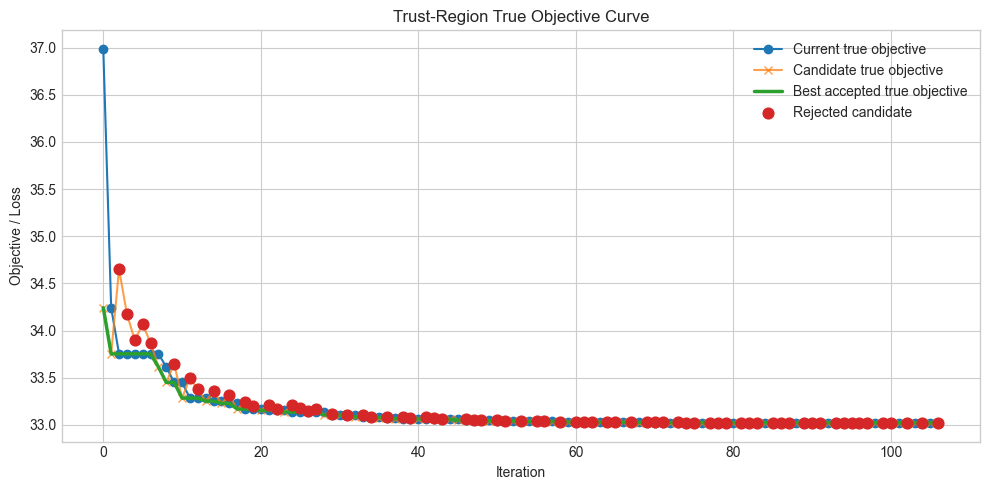

In [36]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(tr_df["k"], tr_df["F_current"], marker="o", label="Current true objective")
ax.plot(tr_df["k"], tr_df["F_candidate"], marker="x", alpha=0.75, label="Candidate true objective")
ax.plot(tr_df["k"], tr_df["best_true_objective"], linewidth=2.5, label="Best accepted true objective")

rejects = tr_df[~tr_df["accepted"]]
ax.scatter(rejects["k"], rejects["F_candidate"], color="tab:red", s=60, label="Rejected candidate", zorder=3)

ax.set_xlabel("Iteration")
ax.set_ylabel("Objective / Loss")
ax.set_title("Trust-Region True Objective Curve")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Compare Three Methods

Zero solver and trust-region curves use cumulative lower-solver calls on the x-axis. The NN solver is shown as a horizontal dashed line at its final true loss.

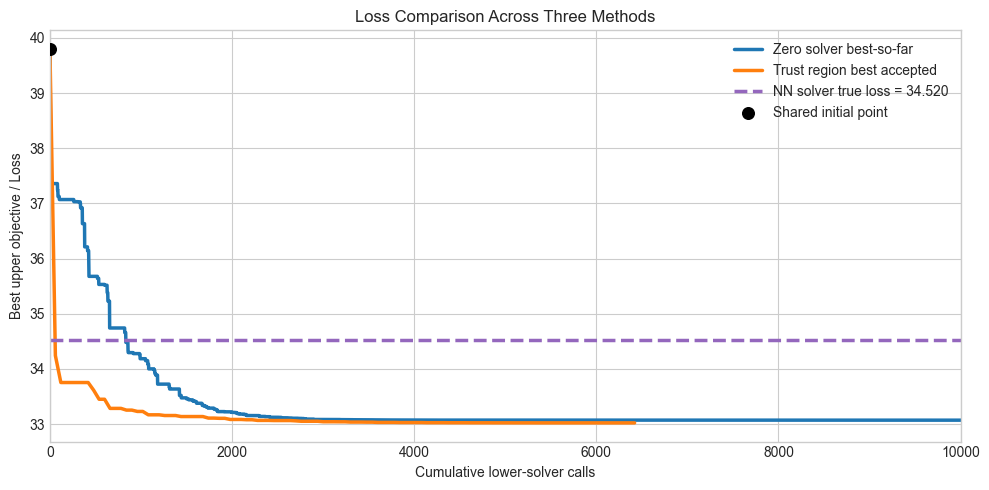

In [38]:
common_initial_objective = float(zero_df["best_so_far_loss"].iloc[0])

tr_plot_df = tr_df.copy()
tr_plot_df["lower_solver_calls"] = (
    tr_plot_df["k"].astype(int) + 1
) * TRUST_REGION_LOWER_CALLS_PER_ITER

tr_plot_df = pd.concat(
    [
        pd.DataFrame(
            {
                "lower_solver_calls": [0],
                "best_true_objective": [common_initial_objective],
                # "best_true_objective": [nn_true_loss],
            }
        ),
        tr_plot_df[["lower_solver_calls", "best_true_objective"]],
    ],
    ignore_index=True,
)
tr_plot_df["best_true_objective"] = tr_plot_df["best_true_objective"].cummin()

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    zero_df["interaction"],
    zero_df["best_so_far_loss"],
    linewidth=2.5,
    label="Zero solver best-so-far",
)
ax.plot(
    tr_plot_df["lower_solver_calls"],
    tr_plot_df["best_true_objective"],
    linewidth=2.5,
    label="Trust region best accepted",
)
ax.axhline(
    nn_true_loss,
    color="tab:purple",
    linestyle="--",
    linewidth=2.5,
    label=f"NN solver true loss = {nn_true_loss:.3f}",
)
ax.scatter(
    [0],
    [common_initial_objective],
    color="black",
    s=70,
    zorder=5,
    label="Shared initial point",
)
PLOT_X_MAX = 10000
ax.set_xlim(0, PLOT_X_MAX)
ax.set_xlabel("Cumulative lower-solver calls")
ax.set_ylabel("Best upper objective / Loss")
ax.set_title("Loss Comparison Across Three Methods")
ax.legend()
fig.tight_layout()
plt.show()